# 08. Arquitectura definitiva de la 1D-CNN

Modificación respecto del modelo histórico del artículo; se mantiene idéntica entre las dos ejecuciones del nuevo dataset.

**Dataset principal:** `data/nuevo_dataset/cardio_train.csv`. Este cuaderno no ejecuta entrenamientos. Los resultados históricos se leen de archivos conservados; no se sustituyen por nuevas ejecuciones.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/nuevo_dataset/cardio_train.csv").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from src.experimento import (
    ORIGINAL, RESULTADOS, VARIABLES, NOMBRES, cargar_datos, reglas_calidad,
    cargar_metricas, comparar_ejecuciones, tabla_configuracion, verificar_configuracion,
    construir_cnn, tabla_modelo, dibujar_arquitectura, guardar_figura_nueva,
    importancia_guardada, resumen_dataset, verificar_predicciones, tensorflow_disponible,
)

In [2]:
import importlib.util
if not tensorflow_disponible():
    print("TensorFlow no esta disponible en este kernel. Se verifica la configuracion del modelo guardado; no se construye ni se ejecuta model.summary().")
    tabla = verificar_configuracion()
    display(tabla)
else:
    import tensorflow as tf
    from tensorflow.keras import Sequential
    from tensorflow.keras.layers import Input, Conv1D, GlobalAveragePooling1D, Dense, Dropout
    model = Sequential([
        Input(shape=(11, 1)),
        Conv1D(32, kernel_size=3, padding="same", activation="relu"),
        Conv1D(96, kernel_size=3, padding="same", activation="relu"),
        GlobalAveragePooling1D(),
        Dense(256, activation="relu"),
        Dropout(0.30),
        Dense(1, activation="sigmoid"),
    ])
    model.summary()
    assert model.count_params() == 34529
    assert 30000 <= model.count_params() <= 50000
    display(tabla_modelo(model))
    tabla = tabla_modelo(model)

TensorFlow no esta disponible en este kernel. Se verifica la configuracion del modelo guardado; no se construye ni se ejecuta model.summary().


,capa,tipo,salida,parametros,filtros,kernel,activacion,padding,unidades,dropout
0,conv1d,Conv1D,"(11, 32)",128,32.0,3.0,relu,same,NaN,NaN
1,conv1d_1,Conv1D,"(11, 96)",9312,96.0,3.0,relu,same,NaN,NaN
2,global_average_pooling1d,GlobalAveragePooling1D,"(96,)",0,NaN,NaN,—,—,NaN,NaN
3,dense,Dense,"(256,)",24832,NaN,NaN,relu,—,256.0,NaN
4,dropout,Dropout,"(256,)",0,NaN,NaN,—,—,NaN,0.3
5,dense_1,Dense,"(1,)",257,NaN,NaN,sigmoid,—,1.0,NaN


## Flujo paso a paso
Entrada `(11,1)`
↓
Conv1D: 32 filtros, kernel 3, ReLU, same → `(11,32)`
↓
Conv1D: 96 filtros, kernel 3, ReLU, same → `(11,96)`
↓
GlobalAveragePooling1D → `(96,)`
↓
Dense 256, ReLU → `(256,)`
↓
Dropout 0.30 → `(256,)`
↓
Dense 1, Sigmoid → probabilidad de `cardio=1`.

Las convoluciones combinan patrones locales en el orden fijo de las 11 variables. No se trata de una serie temporal: ese orden es una decisión del modelado y una limitación que debe explicarse. GlobalAveragePooling promedia sobre las posiciones y evita una capa Flatten de gran dimensión. Dropout no añade parámetros.

Diagrama obtenido de las capas del modelo: D:\UNIVERSIDAD\INGENIERIA DE SISTEMAS\400 PAR\METODOLOGIA DE INVESTIGACION\Cardio\resultados\nuevo_experimento\figuras\reorganizacion\arquitectura_definitiva_desde_codigo.png


08_nueva_arquitectura_cnn:celda-3:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,capa,tipo,salida,parametros,filtros,kernel,activacion,padding,unidades,dropout
0,conv1d,Conv1D,"(11, 32)",128,32.0,3.0,relu,same,NaN,NaN
1,conv1d_1,Conv1D,"(11, 96)",9312,96.0,3.0,relu,same,NaN,NaN
2,global_average_pooling1d,GlobalAveragePooling1D,"(96,)",0,NaN,NaN,—,—,NaN,NaN
3,dense,Dense,"(256,)",24832,NaN,NaN,relu,—,256.0,NaN
4,dropout,Dropout,"(256,)",0,NaN,NaN,—,—,NaN,0.3
5,dense_1,Dense,"(1,)",257,NaN,NaN,sigmoid,—,1.0,NaN


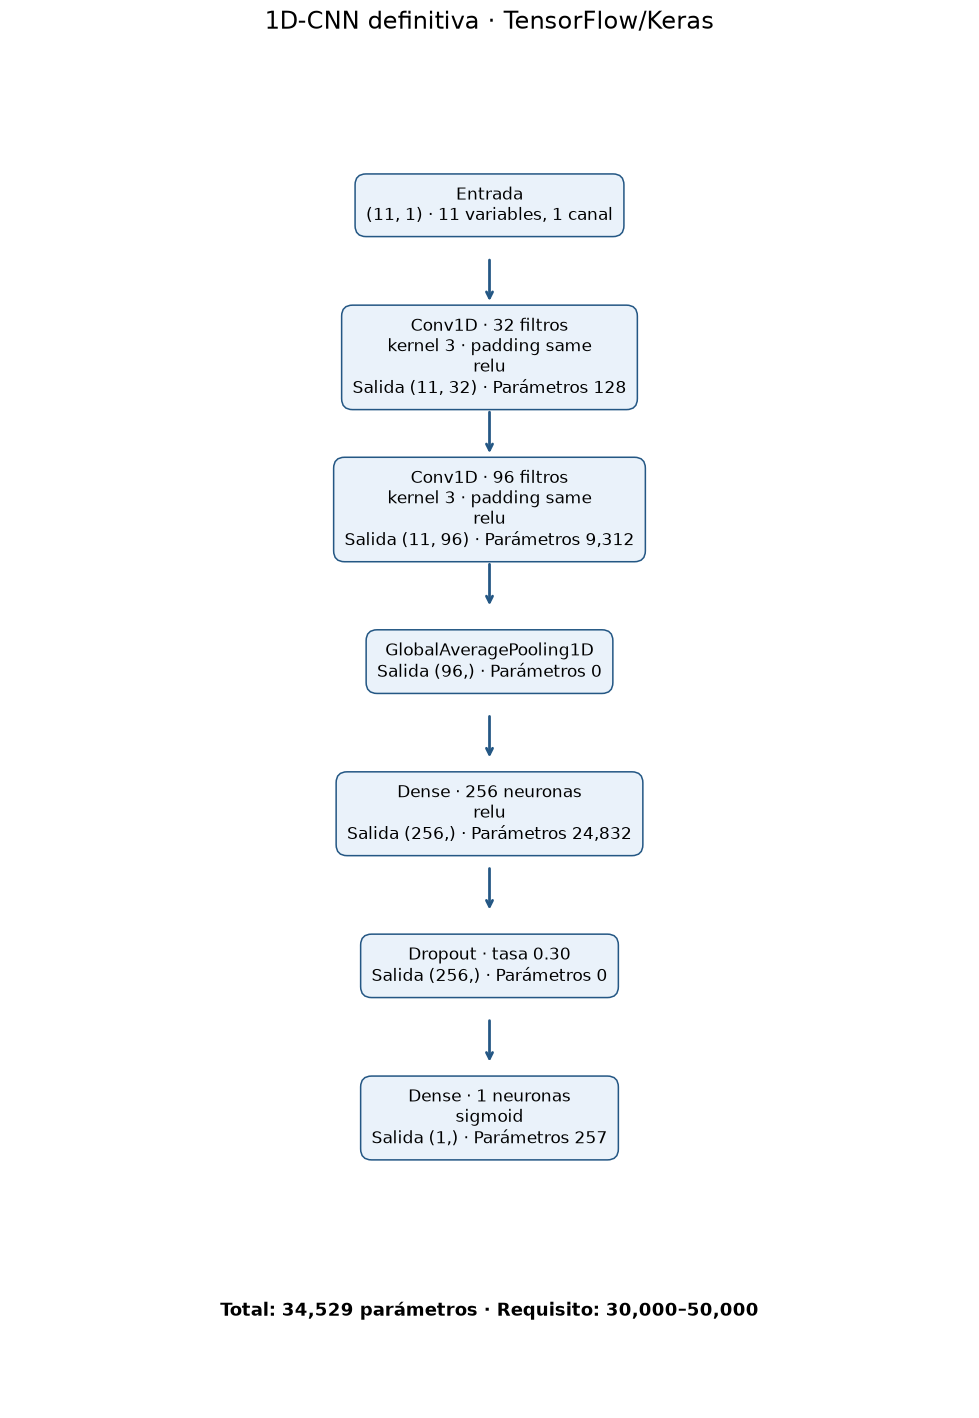

In [3]:
display(tabla)
fig = dibujar_arquitectura(tabla)
ruta = guardar_figura_nueva(fig, "arquitectura_definitiva_desde_codigo.png")
print("Diagrama obtenido de las capas del modelo:", ruta)
plt.show()

## Cálculo de parámetros y requisito del docente
Conv1D(32): `(3 × 1 + 1) × 32 = 128`.

Conv1D(96): `(3 × 32 + 1) × 96 = 9,312`.

Dense(256): `(96 + 1) × 256 = 24,832`.

Dense(1): `(256 + 1) × 1 = 257`.

GlobalAveragePooling1D y Dropout: 0. Total: **34,529**, dentro de **30,000–50,000**. La reducción espacial mediante promedio global permite controlar la entrada de la capa densa y cumplir ese presupuesto. La referencia histórica usaba cuatro convoluciones, normalización por lotes y Flatten; no se reconstruye ni se entrena aquí. Cumplir el rango de parámetros no garantiza por sí mismo mejor rendimiento.

In [4]:
guardado = verificar_configuracion()
assert tabla.parametros.sum() == guardado.parametros.sum() == 34529
print("Arquitectura construida y configuración guardada: 34,529 parámetros.")

Arquitectura construida y configuración guardada: 34,529 parámetros.
